# Exploring the noisier synthetic split

Looks at `train_test_split_data/{train,validation,test}.npz` and the `regime_*/noise_{color}_{level}.npz` files, and compares them with real NGRIP.
Raw data stays untouched; a standardized copy of the noisy series (`z_noisy`) is created in memory with pyleoclim.

Conventions: state `1` = cold (stadial), `0` = warm; a **warming** event is a 1 -> 0 switch.
Noise level `k1` is the weakest and `k0p25` the strongest; in plots they are labeled by SNR = gap / noise std = 1, 0.5, 0.25 (gap = distance between the cold and warm state levels).

In [1]:
import os, json
from itertools import groupby
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import welch
from scipy.ndimage import uniform_filter1d
from sklearn.metrics import roc_auc_score
from ammonyte.utils.metrics import evaluate_detection
from pyleoclim.utils.tsutils import standardize

HERE = os.getcwd()                                  # run from noisier_data/
REGIMES, COLORS, LEVELS = ['15event', '25event', '40event'], ['white', 'pink', 'red'], ['k1', 'k0p5', 'k0p25']
KLAB = {'k1': 'SNR = 1', 'k0p5': 'SNR = 0.5', 'k0p25': 'SNR = 0.25'}     # plot labels; SNR = gap / noise std (= k in the generator)
DT = 0.02                                           # kyr per sample
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def add_z(d):
    d['z_noisy'] = standardize(d['db_noisy'], axis=1)[0]      # per-series z-score (pyleoclim)
    return d

splits = {n: add_z(dict(np.load(f'{HERE}/train_test_split_data/{n}.npz'))) for n in ['train', 'validation', 'test']}
mans = {n: pd.read_csv(f'{HERE}/train_test_split_data/{n}_manifest.csv') for n in splits}
data = {(r, c, l): add_z(dict(np.load(f'{HERE}/regime_{r}/noise_{c}_{l}.npz')))     # all 30 seeds, all 9 combos
        for r in REGIMES for c in COLORS for l in LEVELS}
ng = pd.read_csv(f'{HERE}/../data/NGRIP.csv', comment='#', skiprows=8, header=None).iloc[:, :2].astype(float)
t_ng, y_ng = ng[0].values, ng[1].values                   # NGRIP kept in age order (kyr b2k); flip only needed for detection later
z_ng = standardize(y_ng)[0]

rough = lambda Z: np.diff(Z, axis=1).std(1) / Z.std(1)            # roughness per series
ac1 = lambda Z: np.mean([pd.Series(np.diff(r)).autocorr(1) for r in Z])   # lag-1 autocorr of differences (white -> -0.5)
print({k: v['z_noisy'].shape for k, v in splits.items()}, '| NGRIP', len(y_ng), 'points')

{'train': (60, 6001), 'validation': (30, 6001), 'test': (30, 6001)} | NGRIP 6113 points


## 1. What is in each split

In [2]:
for n, m in mans.items():
    print(f'--- {n}: {len(m)} series'); print(pd.crosstab(m.source, [m.color, m.level]).to_string(), '\n')

--- train: 60 series
color    pink           red         white        
level   k0p25 k0p5 k1 k0p25 k0p5 k1 k0p25 k0p5 k1
source                                           
15event     2    3  2     2    2  2     2    3  2
25event     2    2  3     2    3  2     2    2  2
40event     3    2  2     2    2  3     2    2  2 

--- validation: 30 series
color    pink           red         white        
level   k0p25 k0p5 k1 k0p25 k0p5 k1 k0p25 k0p5 k1
source                                           
15event     1    1  1     1    1  1     2    1  1
25event     1    1  1     2    1  1     1    1  1
40event     1    1  1     1    1  1     2    1  1 

--- test: 30 series
color    pink           red         white        
level   k0p25 k0p5 k1 k0p25 k0p5 k1 k0p25 k0p5 k1
source                                           
25event     4    3  3     3    3  4     3    3  4 



## 2. Warming-event counts per split (NGRIP has about 25)

color  pink               red             white            
level k0p25  k0p5    k1 k0p25  k0p5    k1 k0p25  k0p5    k1
count   4.0   3.0   3.0   3.0   3.0   4.0   3.0   3.0   4.0
mean   23.5  22.7  25.3  23.0  21.7  24.5  25.0  25.0  22.5
min    21.0  21.0  22.0  20.0  20.0  21.0  21.0  23.0  22.0
max    26.0  24.0  28.0  28.0  23.0  28.0  28.0  26.0  23.0


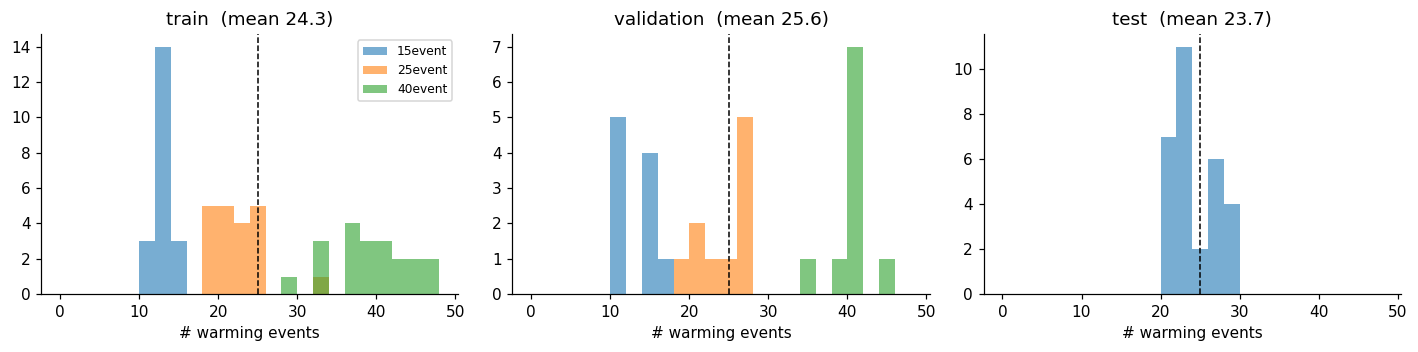

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), sharex=True)
for ax, (n, m) in zip(axes, mans.items()):
    for r, g in m.groupby('source'):
        ax.hist(g.n_warming, bins=np.arange(0, 50, 2), alpha=.6, label=r)
    ax.axvline(25, c='k', ls='--', lw=1)
    ax.set_title(f'{n}  (mean {m.n_warming.mean():.1f})'); ax.set_xlabel('# warming events')
axes[0].legend(fontsize=8); fig.tight_layout()
print(mans['test'].groupby(['color', 'level']).n_warming.agg(['count', 'mean', 'min', 'max']).T.round(1).to_string())

## 3. Timing: waiting time between warmings, per regime

Time between successive warmings (1 -> 0 switches of `state_true`) in each event-count regime (15, 25, 40), all 30 seeds, vs the NGRIP DO onsets (Rasmussen 2014, 25 main events). `state_true` is identical across noise colors/levels, so one combo per regime is used. Statistics are in the legend labels.


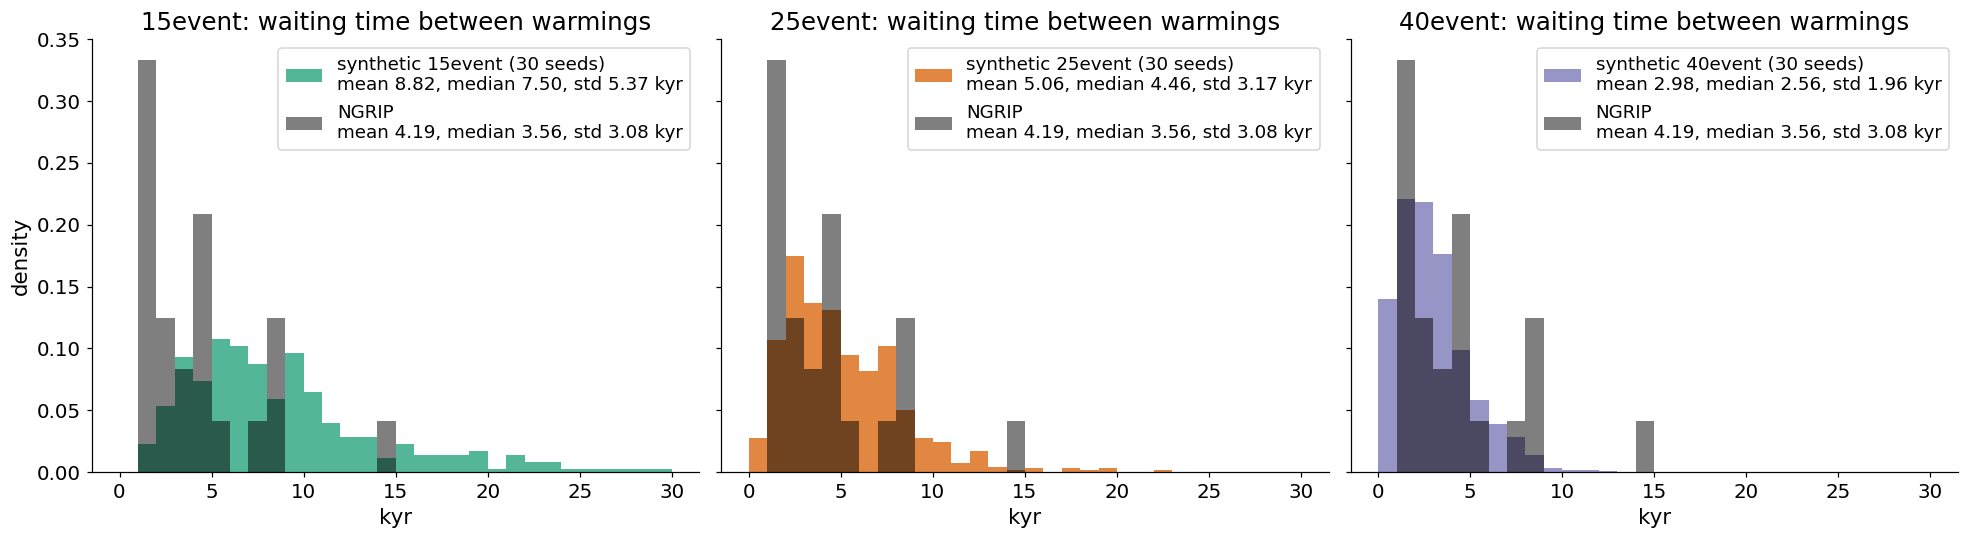

In [4]:
DO_CSV = '/Users/maryamniati/Documents/Ammonyte/ammonyte/ammonyte/data/DO_onsets_Rasmussen2014.csv'
wait_ng = np.diff(np.sort(pd.read_csv(DO_CSV, comment='#')['main25_kyr_b2k'].dropna().values))
stats = lambda v: f'mean {np.mean(v):.2f}, median {np.median(v):.2f}, std {np.std(v):.2f}'
bins = np.arange(0, 30.5, 1)
REGIME_COLORS = {'15event': '#1b9e77', '25event': '#d95f02', '40event': '#7570b3'}      # distinct from the noise colors
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, r in zip(axes, REGIMES):
    S = data[(r, 'white', 'k1')]['state_true']                                 # same true states in every color/level
    wait = np.concatenate([np.diff(np.nonzero(np.diff(s) == -1)[0] * DT) for s in S])   # kyr between successive warmings
    ax.hist(wait, bins=bins, density=True, alpha=.75, color=REGIME_COLORS[r], label=f'synthetic {r} (30 seeds)\n{stats(wait)} kyr')
    ax.hist(wait_ng, bins=bins, density=True, alpha=.5, color='k', label=f'NGRIP\n{stats(wait_ng)} kyr')
    ax.set_title(f'{r}: waiting time between warmings', fontsize=16); ax.set_xlabel('kyr', fontsize=14); ax.tick_params(labelsize=13)
    ax.legend(fontsize=12, loc='upper right')
axes[0].set_ylabel('density', fontsize=14); fig.tight_layout()


## 4. What the test series look like

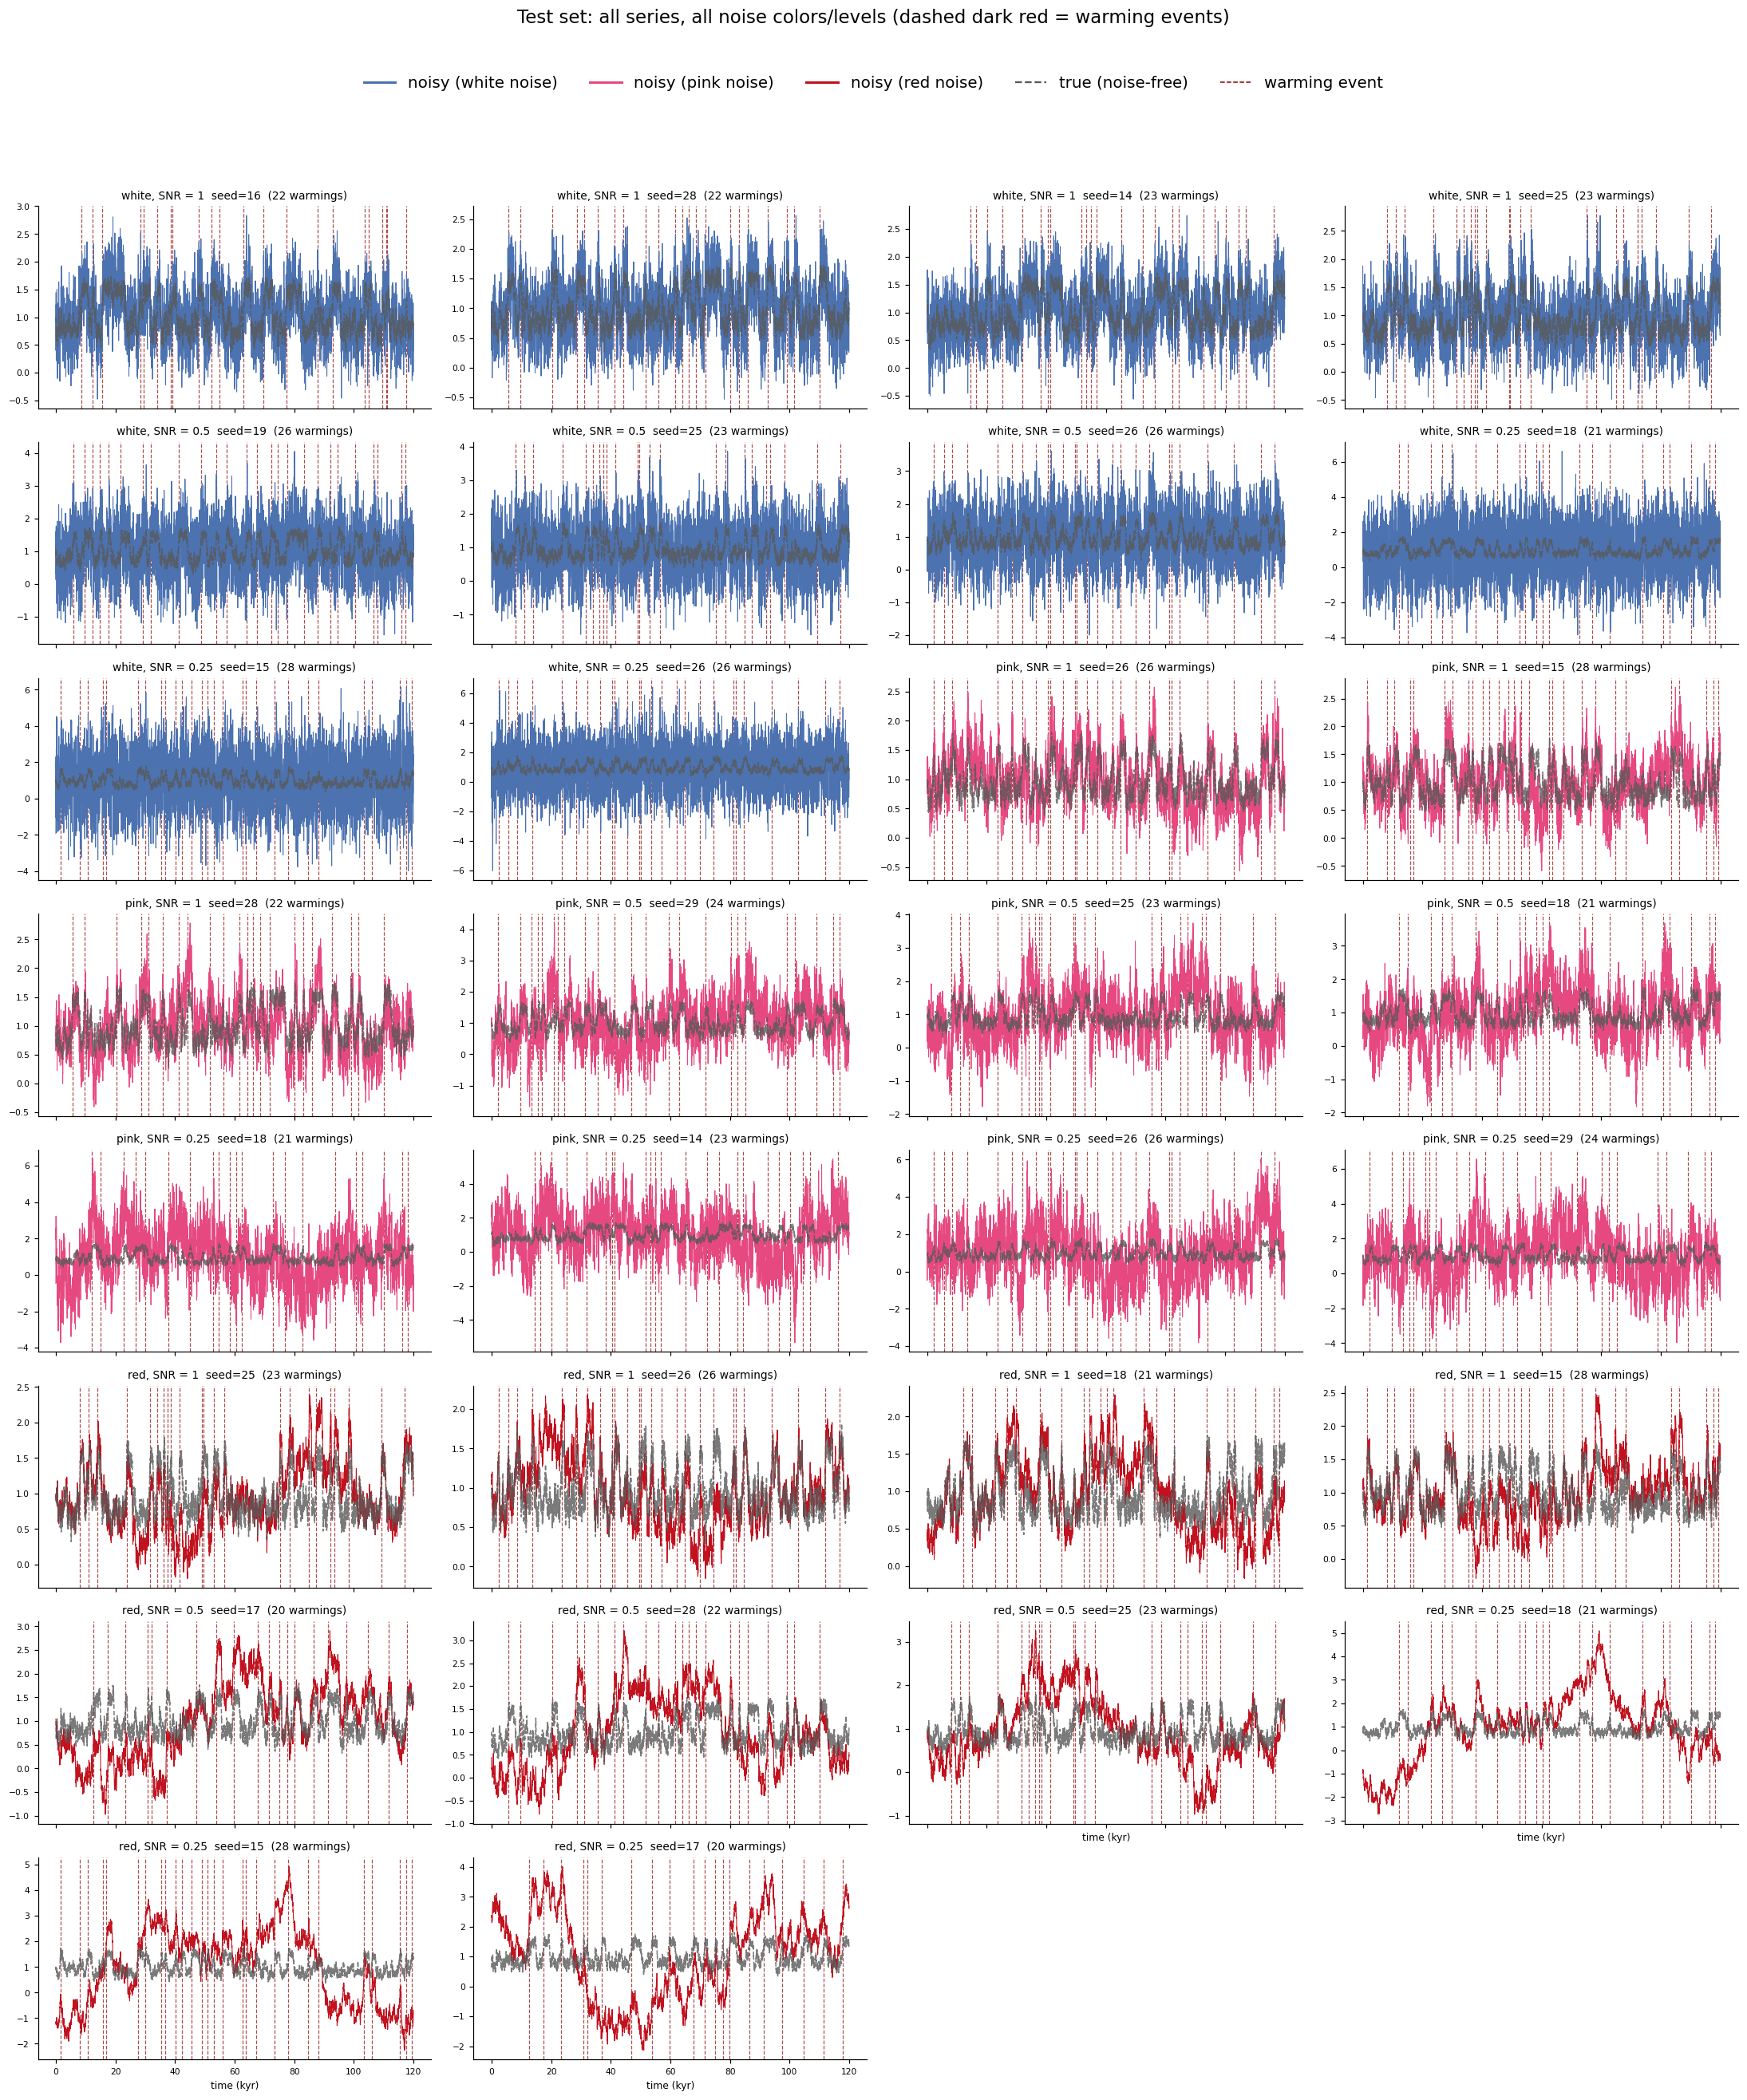

In [5]:
WARM_COLOR = '#8b0000'
NOISE_COLORS = {'white': '#4c72b0', 'pink': '#e64980', 'red': '#c1121f'}
T, m = splits['test'], mans['test']
order = sorted(range(len(m)), key=lambda k: (COLORS.index(m.color[k]), LEVELS.index(m.level[k])))   # by color, then k1 -> k0p25
ncols = 4
nrows = int(np.ceil(len(order) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.0 * nrows), sharex=True)
for ax, k in zip(axes.flat, order):
    ax.plot(T['time'], T['db_noisy'][k], lw=.7, c=NOISE_COLORS[m.color[k]], label='noisy')
    ax.plot(T['time'], T['db_true'][k], lw=1, c='#595959', ls='--', alpha=.8, label='true')
    for t in T['time'][1:][np.diff(T['state_true'][k]) == -1]:
        ax.axvline(t, c=WARM_COLOR, ls='--', lw=.8, alpha=.7, zorder=0)
    ax.set_title(f"{m.color[k]}, {KLAB[m.level[k]]}  seed={m.orig_seed[k]}  ({m.n_warming[k]} warmings)", fontsize=9); ax.tick_params(labelsize=7)
for ax in axes.flat[len(order):]:
    ax.axis('off')
for ax in axes.flat[len(order) - ncols:len(order)]:
    ax.set_xlabel('time (kyr)', fontsize=8)
fig.suptitle('Test set: all series, all noise colors/levels (dashed dark red = warming events)', fontsize=15, y=0.995)
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([], [], c=NOISE_COLORS[c], lw=2, label=f'noisy ({c} noise)') for c in COLORS] +
           [Line2D([], [], c='#595959', ls='--', lw=1.5, label='true (noise-free)'), Line2D([], [], c=WARM_COLOR, ls='--', lw=1, label='warming event')],
           loc='upper center', ncol=5, fontsize=13, frameon=False, bbox_to_anchor=(0.5, 0.97))
fig.tight_layout(rect=(0, 0, 1, 0.93))

### Same true trajectory under all 9 noise settings (how much noise changes the signal)

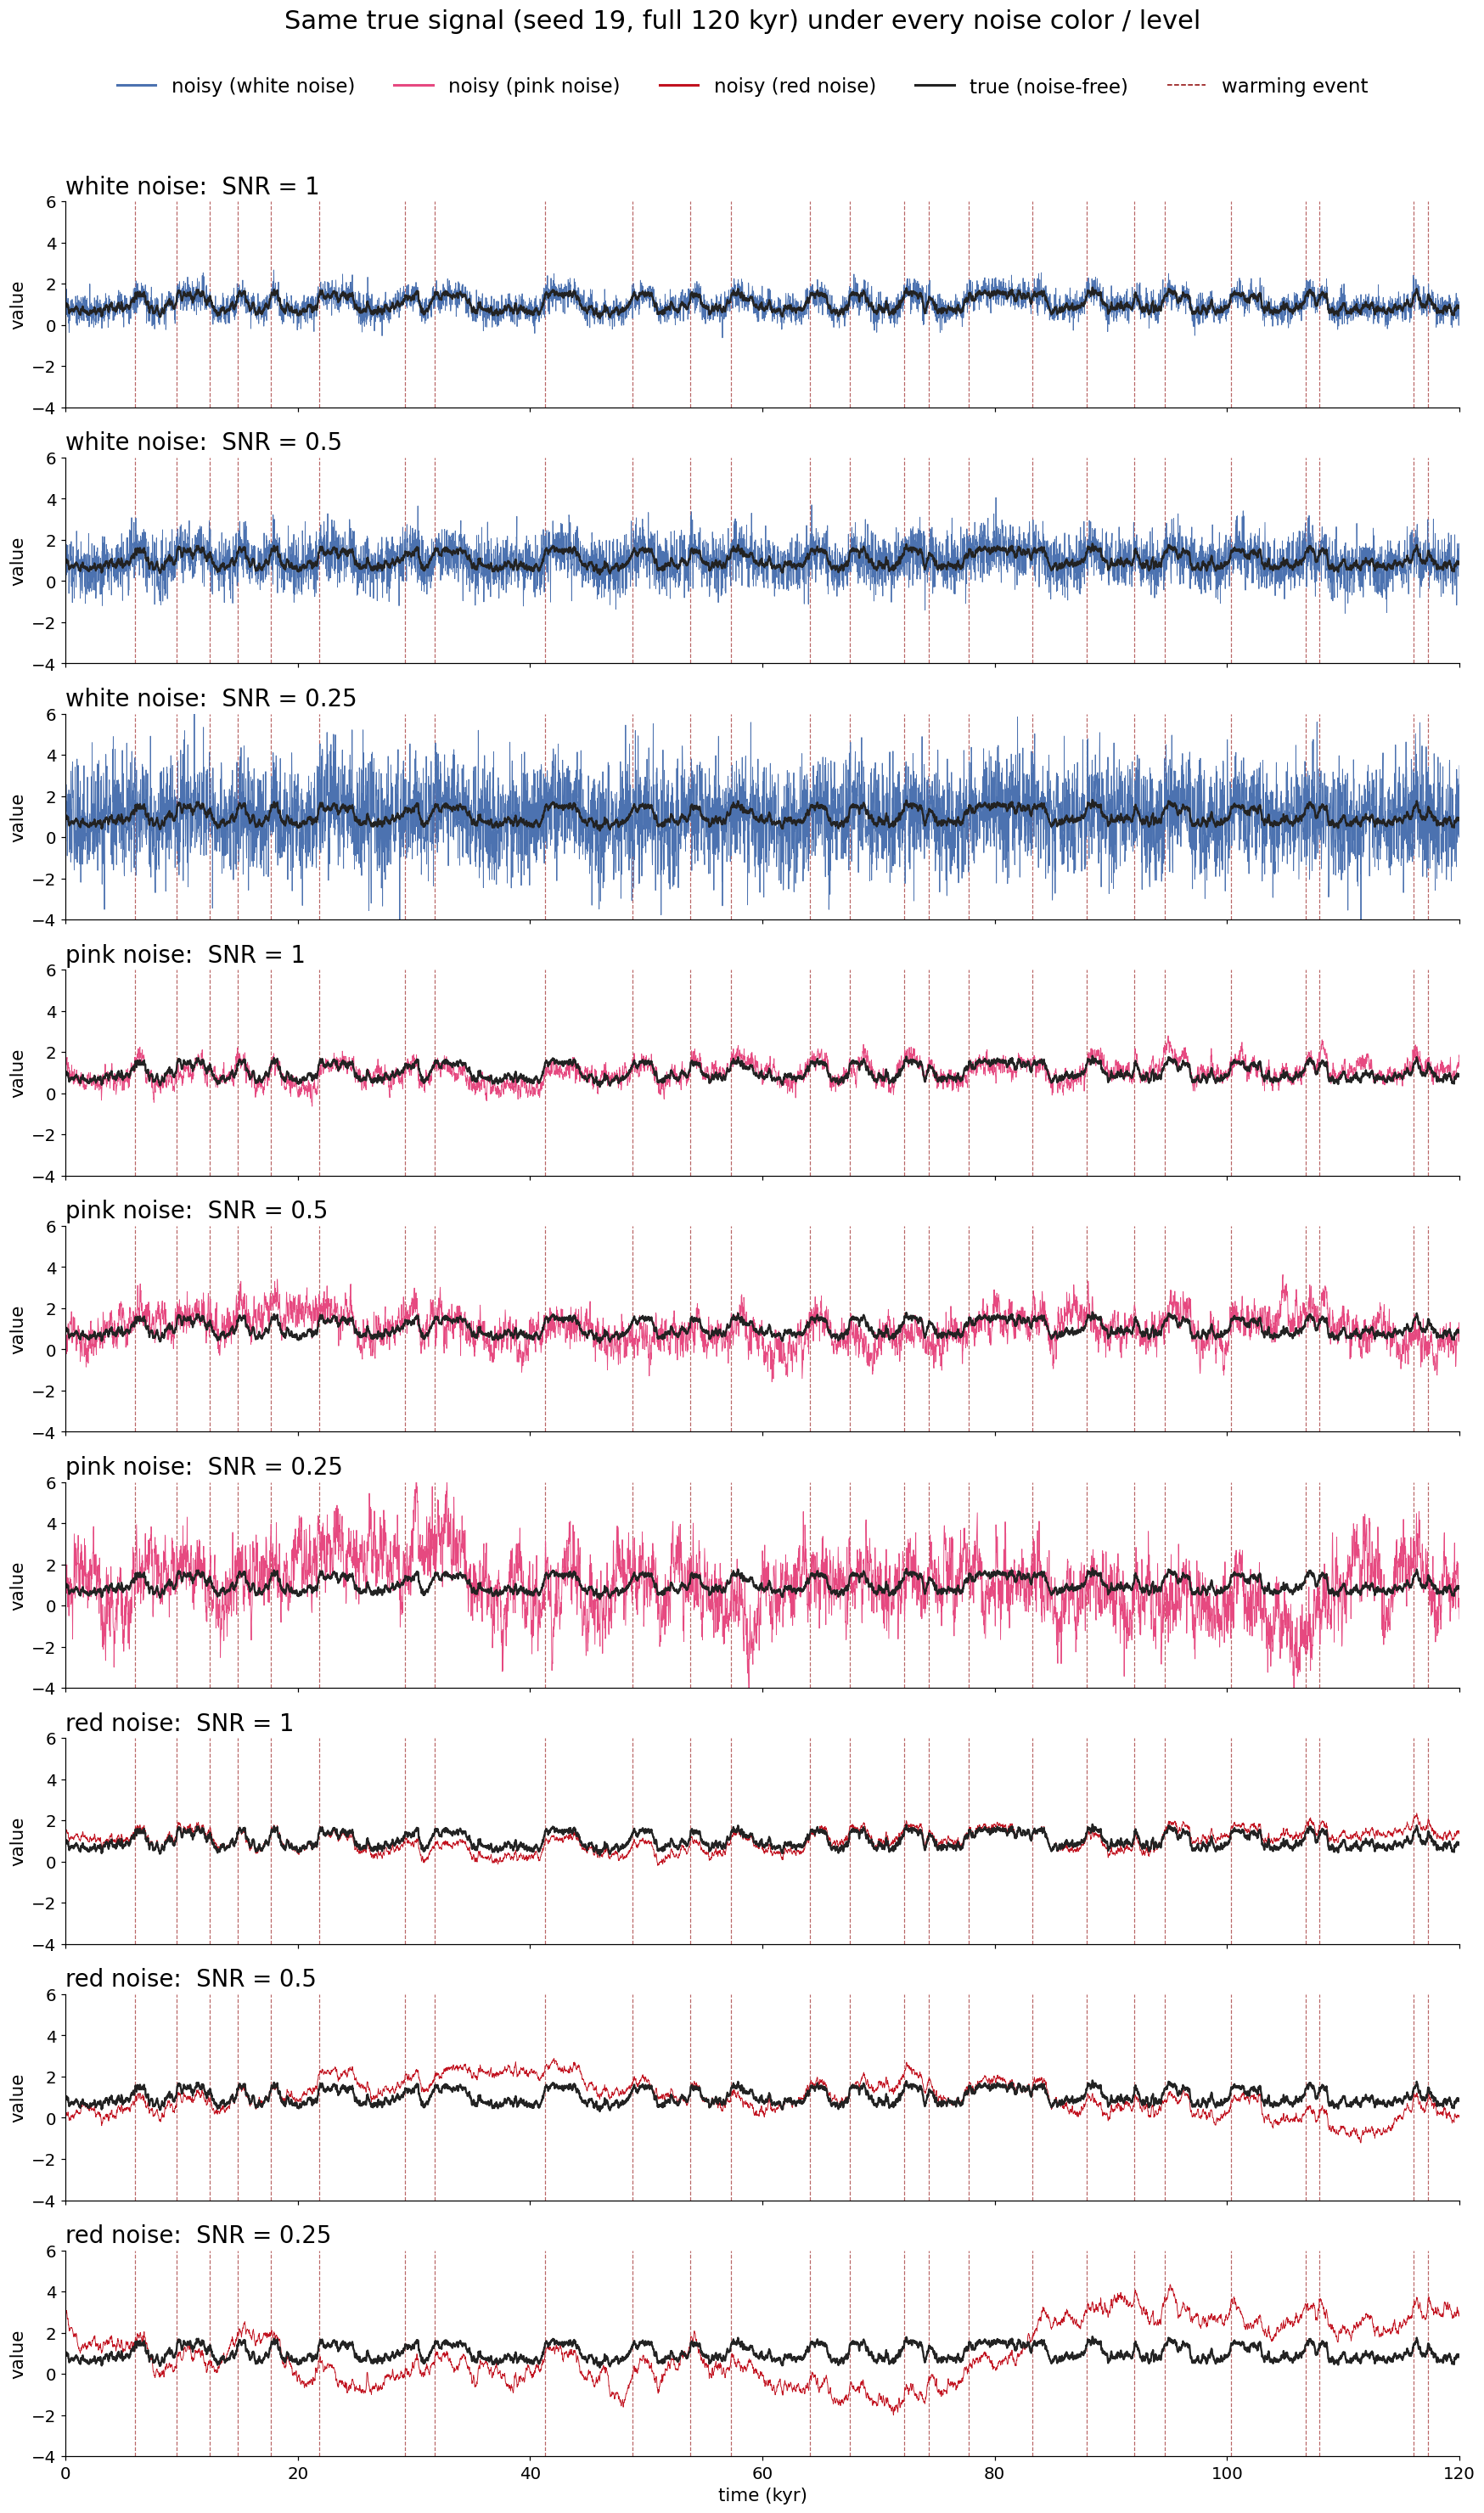

In [6]:
SEED = 19                                            # a test seed (26 warmings); same true trajectory in all 9 panels
K = {'k1': 1, 'k0p5': 0.5, 'k0p25': 0.25}              # std(noise) = gap / k
GAP = json.load(open(f'{HERE}/regime_25event/noise_grid_config.json'))['gap']
combos = [(c, l) for c in COLORS for l in LEVELS]   # grouped by color, noise grows k1 -> k0p25 within each color
fig, axes = plt.subplots(len(combos), 1, figsize=(16, 3 * len(combos)), sharex=True, sharey=True)
for ax, (c, l) in zip(axes, combos):
    d = data[('25event', c, l)]
    ax.plot(d['time'], d['db_noisy'][SEED], lw=.6, c=NOISE_COLORS[c], label='noisy')
    ax.plot(d['time'], d['db_true'][SEED], lw=1.5, c='#222', label='true')
    for t in d['time'][1:][np.diff(d['state_true'][SEED]) == -1]:
        ax.axvline(t, c=WARM_COLOR, ls='--', lw=.8, alpha=.6, zorder=0)
    ax.set_title(f'{c} noise:  SNR = {K[l]:g}', fontsize=18, loc='left')
    ax.set_ylabel('value', fontsize=14); ax.tick_params(labelsize=13)
axes[0].set_ylim(-4, 6); axes[0].set_xlim(0, 120)
axes[-1].set_xlabel('time (kyr)', fontsize=14)
fig.suptitle(f'Same true signal (seed {SEED}, full 120 kyr) under every noise color / level', fontsize=20, y=0.995)
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([], [], c=NOISE_COLORS[c], lw=2, label=f'noisy ({c} noise)') for c in COLORS] +
           [Line2D([], [], c='#222', lw=2, label='true (noise-free)'), Line2D([], [], c=WARM_COLOR, ls='--', lw=1, label='warming event')],
           loc='upper center', ncol=5, fontsize=15, frameon=False, bbox_to_anchor=(0.5, 0.975))
fig.tight_layout(rect=(0, 0, 1, 0.95))

## 5. Is the noise strong enough?

All 30 `25event` seeds per (color, level) vs NGRIP. `SNR_std` = std(true) / std(noisy - true), computed on the raw data (about 0.92 x the nominal SNR used in plot labels, because std(true) is slightly below the gap).

In [7]:
rows = []
for c in COLORS:
    for l in LEVELS:
        d = data[('25event', c, l)]
        rows.append(dict(color=c, level=l, SNR_std=(d['db_true'].std(1) / (d['db_noisy'] - d['db_true']).std(1)).mean(),
                         roughness=rough(d['z_noisy']).mean(), diff_ac1=ac1(d['z_noisy'])))
rows.append(dict(color='NGRIP', level='real', SNR_std=np.nan, roughness=rough(z_ng[None])[0], diff_ac1=ac1(z_ng[None])))
print(pd.DataFrame(rows).round(3).to_string(index=False))

color level  SNR_std  roughness  diff_ac1
white    k1    0.909      1.058    -0.492
white  k0p5    0.455      1.289    -0.498
white k0p25    0.227      1.379    -0.499
 pink    k1    0.909      0.486    -0.241
 pink  k0p5    0.455      0.572    -0.255
 pink k0p25    0.227      0.606    -0.259
  red    k1    0.909      0.148    -0.026
  red  k0p5    0.455      0.096    -0.005
  red k0p25    0.227      0.062     0.048
NGRIP  real      NaN      0.303    -0.392


### Raw-scale check (before standardizing)

Standardizing removes mean and amplitude, so realism of the amplitude has to be judged on the raw values first.
The synthetic `db_*` series are in arbitrary units, not d18O, so NGRIP's absolute numbers are not directly comparable. Compare *relative* quantities instead:
the cold-warm gap relative to the total spread, and the noise standard deviation relative to the gap.
`gap_split` separates each series at its own mean (same estimator for synthetic and NGRIP); `gap_state` uses the true states (synthetic only).

In [8]:
def gap_split(Y):
    return np.array([y[y > y.mean()].mean() - y[y <= y.mean()].mean() for y in np.atleast_2d(Y)])

rows = []
for c in COLORS:
    for l in LEVELS:
        d = data[('25event', c, l)]; Y, S = d['db_noisy'], d['state_true']
        gap_state = np.array([y[s == 1].mean() - y[s == 0].mean() for y, s in zip(Y, S)])
        noise_sd = (Y - d['db_true']).std(1)
        rows.append(dict(color=c, level=l, mean=Y.mean(), std=Y.std(1).mean(), range=np.ptp(Y, axis=1).mean(),
                         gap_state=np.abs(gap_state).mean(), gap_split=gap_split(Y).mean(),
                         gap_over_std=(gap_split(Y) / Y.std(1)).mean(), noise_over_gap=(noise_sd / np.abs(gap_state)).mean()))
rows.append(dict(color='NGRIP', level='real', mean=y_ng.mean(), std=y_ng.std(), range=np.ptp(y_ng),
                 gap_split=gap_split(y_ng)[0], gap_over_std=gap_split(y_ng)[0] / y_ng.std()))
print(pd.DataFrame(rows).round(3).to_string(index=False))

color level    mean   std  range  gap_state  gap_split  gap_over_std  noise_over_gap
white    k1   0.992 0.475  3.229      0.608      0.767         1.615           0.579
white  k0p5   0.992 0.774  5.756      0.614      1.236         1.597           1.149
white k0p25   0.992 1.444 10.902      0.617      2.308         1.598           2.287
 pink    k1   0.992 0.472  3.177      0.598      0.762         1.614           0.594
 pink  k0p5   0.992 0.773  5.449      0.608      1.235         1.598           1.228
 pink k0p25   0.992 1.444 10.406      0.603      2.305         1.597           2.905
  red    k1   0.992 0.477  2.509      0.615      0.779         1.632           0.582
  red  k0p5   0.992 0.775  3.937      0.616      1.280         1.651           1.195
  red k0p25   0.992 1.441  6.783      0.583      2.415         1.676           3.285
NGRIP  real -39.942 2.968 14.390        NaN      4.901         1.651             NaN


Raw series (no standardization): NGRIP and one test series at noise level `k0p5`, each on its own y-axis because the units differ.

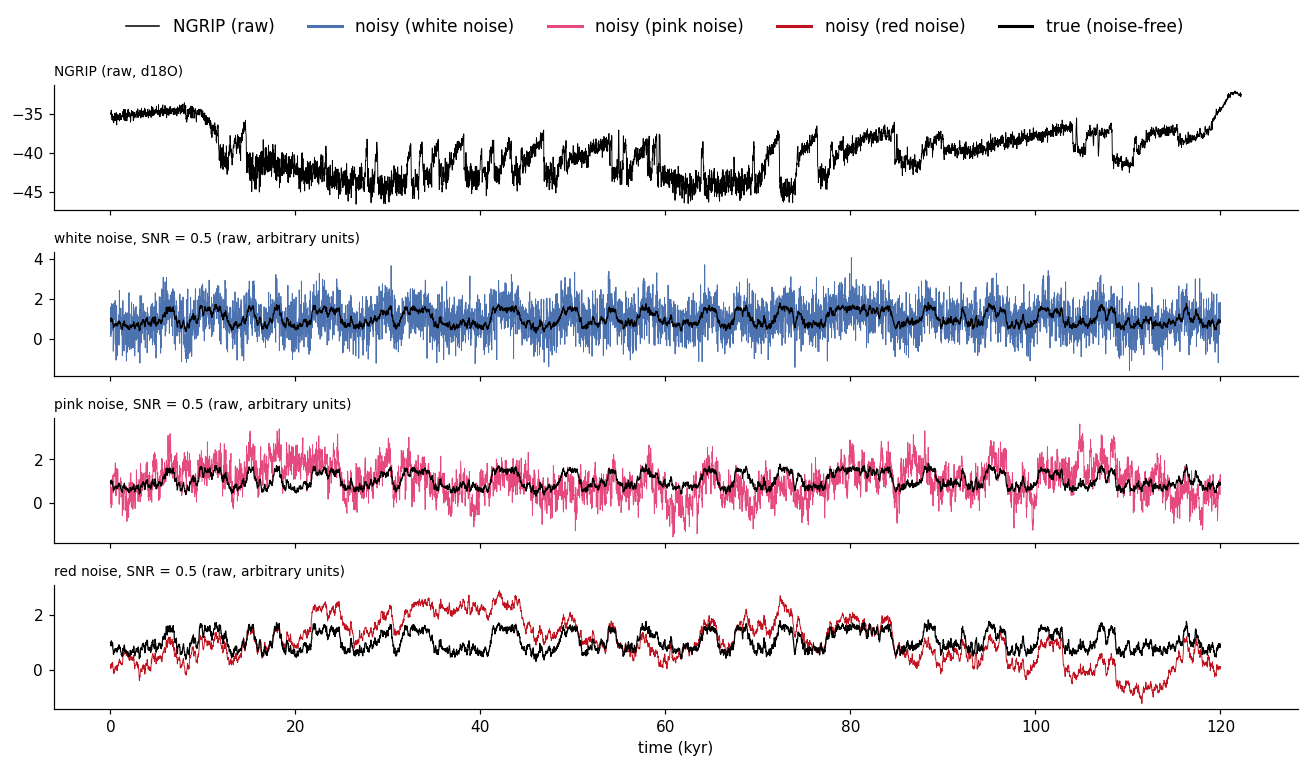

In [9]:
fig, axes = plt.subplots(4, 1, figsize=(12, 7), sharex=True)
axes[0].plot(t_ng, y_ng, c='k', lw=.6); axes[0].set_title('NGRIP (raw, d18O)', fontsize=9, loc='left')
for ax, c in zip(axes[1:], COLORS):
    d = data[('25event', c, 'k0p5')]
    ax.plot(d['time'], d['db_noisy'][SEED], c=NOISE_COLORS[c], lw=.6); ax.plot(d['time'], d['db_true'][SEED], c='k', lw=.8)
    ax.set_title(f'{c} noise, {KLAB["k0p5"]} (raw, arbitrary units)', fontsize=9, loc='left')
axes[-1].set_xlabel('time (kyr)')
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([], [], c='k', lw=1, label='NGRIP (raw)')] + [Line2D([], [], c=NOISE_COLORS[c], lw=2, label=f'noisy ({c} noise)') for c in COLORS] +
           [Line2D([], [], c='k', lw=2, label='true (noise-free)')], loc='upper center', ncol=5, fontsize=11, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.94))

Absolute (raw) power spectra of the synthetic series: shows how much power the noise adds. NGRIP is left out because its units differ.

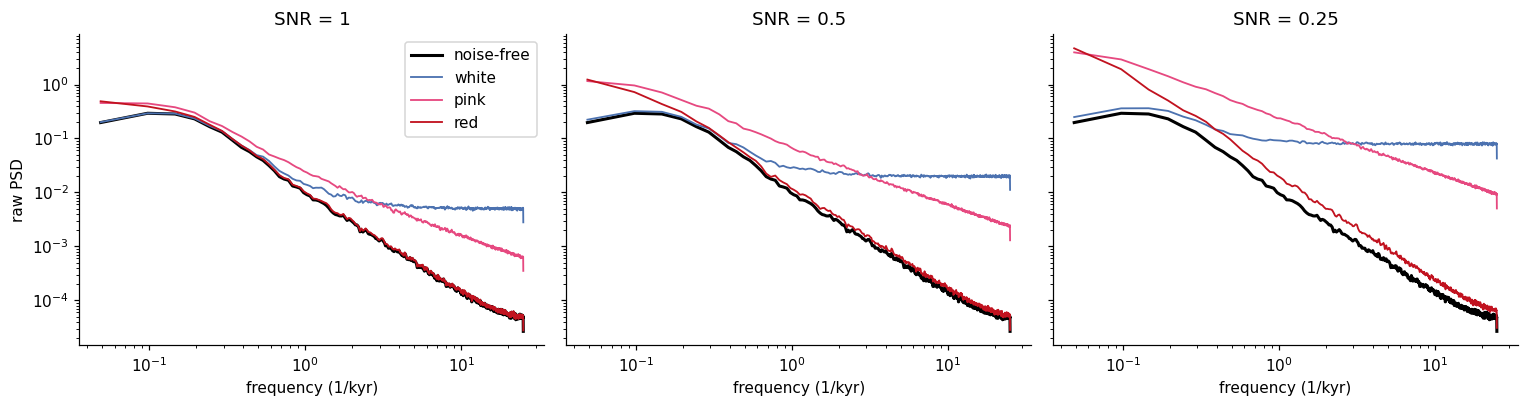

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, l in zip(axes, LEVELS):
    f, P0 = welch(data[('25event', 'white', l)]['db_true'], fs=1 / DT, nperseg=1024, axis=1)
    ax.loglog(f[1:], P0.mean(0)[1:], c='k', lw=2, label='noise-free')
    for c in COLORS:
        P = welch(data[('25event', c, l)]['db_noisy'], fs=1 / DT, nperseg=1024, axis=1)[1].mean(0)
        ax.loglog(f[1:], P[1:], c=NOISE_COLORS[c], lw=1.2, label=c)
    ax.set_title(KLAB[l]); ax.set_xlabel('frequency (1/kyr)')
axes[0].set_ylabel('raw PSD'); axes[0].legend(); fig.tight_layout()

### Power spectra vs NGRIP

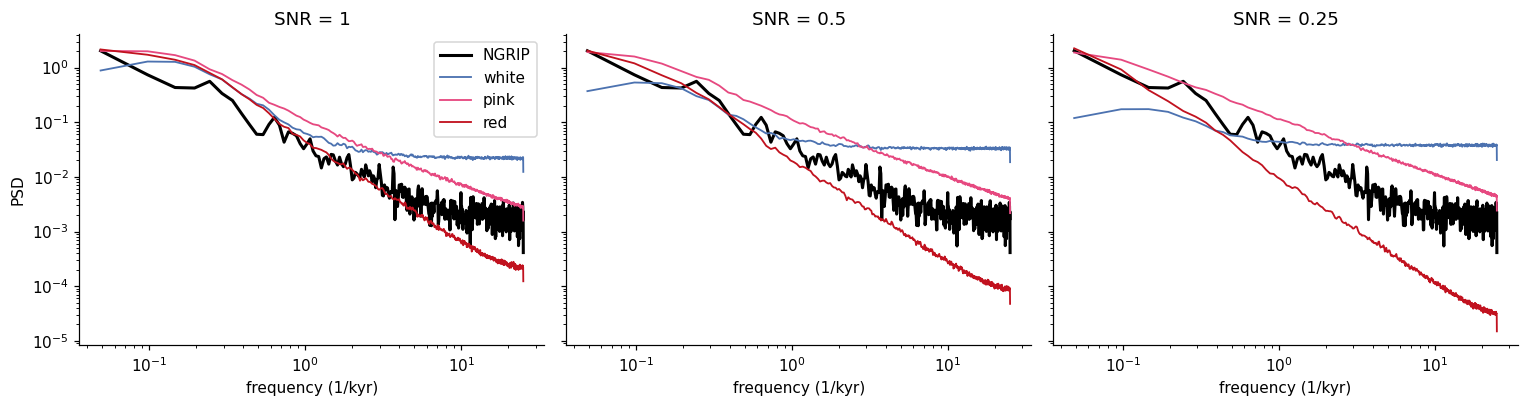

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
f, p_ng = welch(z_ng, fs=1 / DT, nperseg=1024)
for ax, l in zip(axes, LEVELS):
    ax.loglog(f[1:], p_ng[1:], c='k', lw=2, label='NGRIP')
    for c in COLORS:
        P = welch(data[('25event', c, l)]['z_noisy'], fs=1 / DT, nperseg=1024, axis=1)[1].mean(0)
        ax.loglog(f[1:], P[1:], c=NOISE_COLORS[c], lw=1.2, label=c)
    ax.set_title(KLAB[l]); ax.set_xlabel('frequency (1/kyr)')
axes[0].set_ylabel('PSD'); axes[0].legend(); fig.tight_layout()

### Do the two states overlap? (standardized noisy values by true state; AUC = how well value alone separates the states)

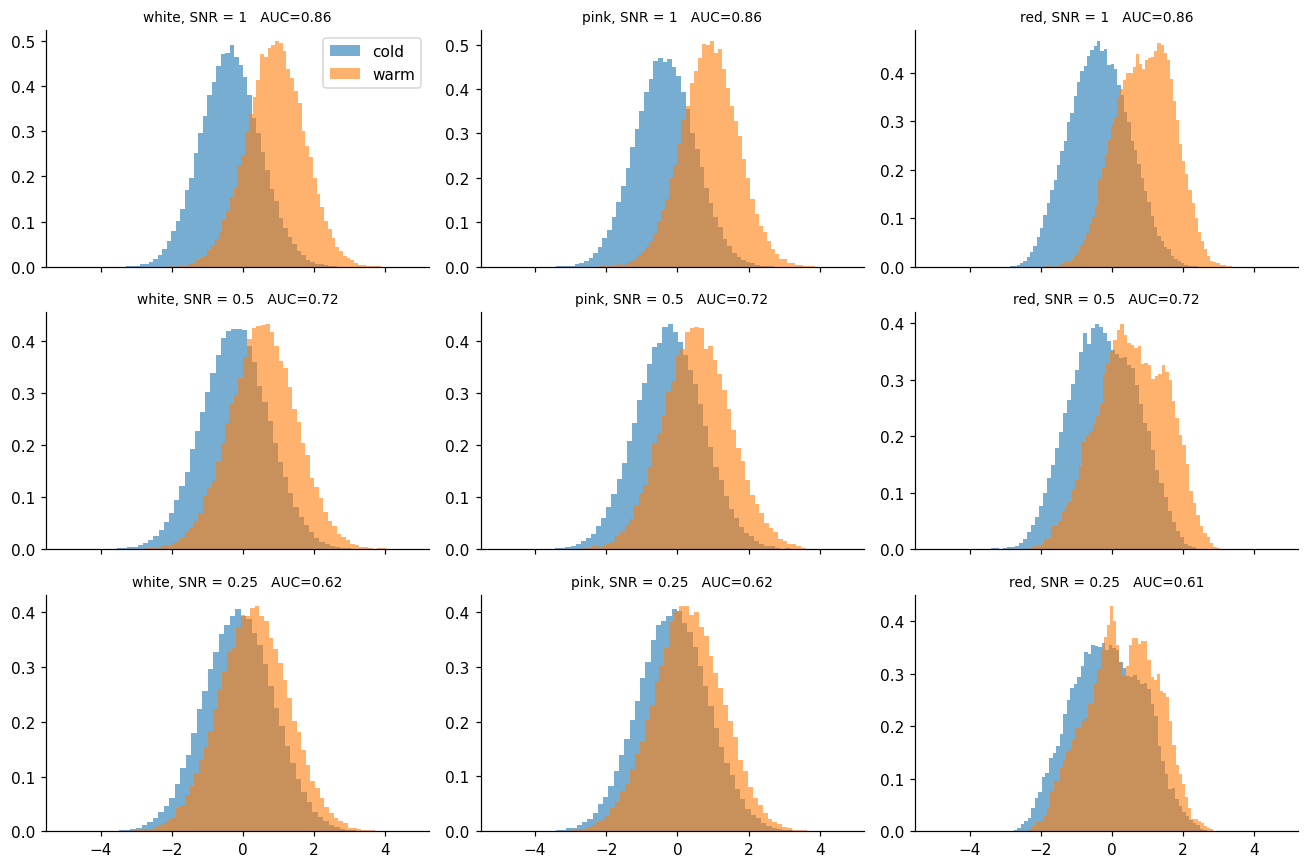

In [12]:
fig, axes = plt.subplots(3, 3, figsize=(12, 8), sharex=True)
for i, l in enumerate(LEVELS):
    for j, c in enumerate(COLORS):
        d = data[('25event', c, l)]; y, s = d['z_noisy'].ravel(), d['state_true'].ravel()
        axes[i, j].hist(y[s == 1], bins=60, alpha=.6, density=True, label='cold'); axes[i, j].hist(y[s == 0], bins=60, alpha=.6, density=True, label='warm')
        axes[i, j].set_title(f'{c}, {KLAB[l]}   AUC={max(roc_auc_score(s, y), 1 - roc_auc_score(s, y)):.2f}', fontsize=9)
axes[0, 0].legend(); fig.tight_layout()

### Simple baseline: threshold crossing, scored with ±0.5 kyr tolerance

Smooth the standardized series, call a **warming** wherever it crosses its mean (z = 0) upward, and score those times against the true
warming times with ammonyte's `evaluate_detection` and `tolerance=0.5` kyr (the same matching used in `optuna_search.py`).
No fitting, so train + validation + test are all pooled per (color, level). Very high F1 = noise too weak; very low = too strong.

In [13]:
TOL = 0.5
def baseline(win):
    out = {}
    for c in COLORS:
        for l in LEVELS:
            tp = fp = fn = 0
            for n in splits:
                k = ((mans[n].color == c) & (mans[n].level == l)).values
                t = splits[n]['time'][1:]
                for zs, st in zip(uniform_filter1d(splits[n]['z_noisy'][k], win, axis=1), splits[n]['state_true'][k]):
                    det = t[np.diff((zs > 0).astype(int)) == 1]                  # upward crossing = warming
                    gt = t[np.diff(st) == -1]                                    # true warmings (1 -> 0)
                    m = evaluate_detection(det, gt, tolerance=TOL)
                    tp += m.true_positives; fp += m.false_positives; fn += m.false_negatives
            p, r = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
            out[(c, l)] = dict(precision=p, recall=r, F1=2 * p * r / max(p + r, 1e-9))
    return pd.DataFrame(out).T

for win in (25, 100):
    print(f'smoothing window = {win} samples ({win * DT:.1f} kyr)'); print(baseline(win).round(3).to_string(), '\n')

smoothing window = 25 samples (0.5 kyr)
             precision  recall     F1
white k1         0.372   0.784  0.505
      k0p5       0.165   0.778  0.273
      k0p25      0.126   0.845  0.219
pink  k1         0.342   0.638  0.445
      k0p5       0.217   0.477  0.298
      k0p25      0.241   0.456  0.315
red   k1         0.500   0.497  0.499
      k0p5       0.390   0.242  0.299
      k0p25      0.342   0.169  0.227 

smoothing window = 100 samples (2.0 kyr)
             precision  recall     F1
white k1         0.385   0.325  0.353
      k0p5       0.223   0.358  0.274
      k0p25      0.150   0.346  0.210
pink  k1         0.336   0.282  0.307
      k0p5       0.245   0.212  0.227
      k0p25      0.268   0.186  0.220
red   k1         0.389   0.161  0.228
      k0p5       0.329   0.086  0.136
      k0p25      0.226   0.047  0.077 



## How to read this

* **Event counts / timing:** test series should sit in 20-30 warmings; the 25-event waiting times should be close to NGRIP's (the 15- and 40-event regimes are slower and faster by design).
* **Roughness & spectra:** noisy series should match NGRIP's roughness (~0.3) and spectral slope. Much smoother = too weak or wrong color; much rougher = too strong.
* **AUC and baseline F1:** near 1 means too easy; near 0 (F1) or 0.5 (AUC) means the noise swamps the signal.